# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
import pandas as pd
df = pd.read_csv('Cleaned_AviationData.csv', low_memory=False)

print(df.shape)
display(df.head())

(63067, 35)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total_Passengers,Serious_Fatal_Fraction,Is.Destroyed,Make.Model
0,20001214X42040,Accident,LAX83LA093,1983-01-01,"ARROYO GRANDE, CA",United States,NaN,NaN,NaN,NaN,...,0.0,1.0,Vmc,Landing,Probable Cause,NaN,2.0,0.5,NaN,PICCARD_AX-6
1,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,Vmc,Approach,Probable Cause,NaN,4.0,0.0,0.0,CESSNA_182P
2,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,Vmc,Landing,Probable Cause,NaN,2.0,0.0,0.0,CESSNA_182RG
3,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,Vmc,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,CESSNA_182P
4,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,Vmc,Approach,Probable Cause,NaN,2.0,0.0,0.0,PIPER_PA-28R-200


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [10]:
# Separate datasets based on total occupants threshold (20)
df_small = df[df['Total_Passengers'] <= 20].copy()
df_large = df[df['Total_Passengers'] > 20].copy()

print(f"Small aircraft records (Passengers <= 20): {df_small.shape[0]}")
print(f"Larger aircraft records (Passengers > 20): {df_large.shape[0]}")

Small aircraft records (Passengers <= 20): 60931
Larger aircraft records (Passengers > 20): 2136


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\3896814061.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=small_make_injury['mean'], y=small_make_injury.index, ax=axes[0], palette='Blues_r')
C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\3896814061.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=large_make_injury['mean'], y=large_make_injury.index, ax=axes[1], palette='Greens_r')


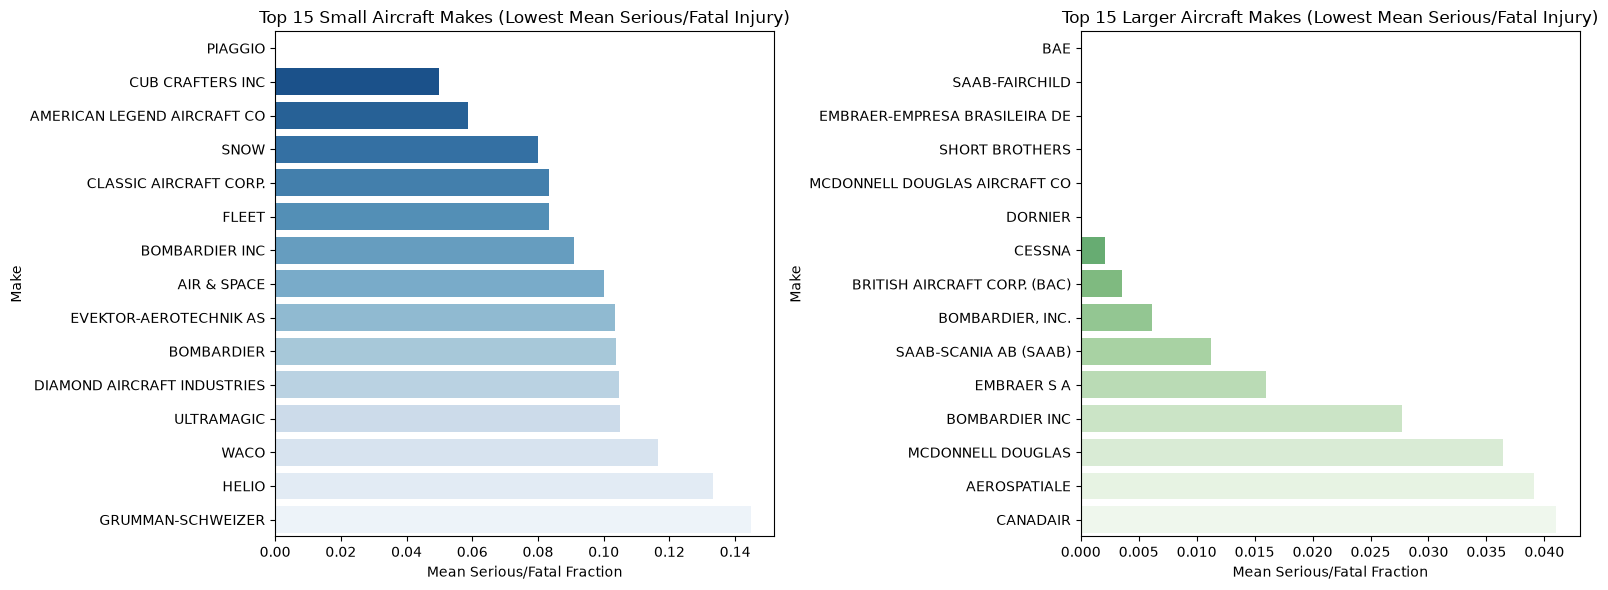

In [32]:
# Calculate mean injury fraction for small and large makes (minimum sample threshold applied)
small_make_injury = df_small.groupby('Make')['Serious_Fatal_Fraction'].agg(['mean', 'count']).query('count >= 10').sort_values('mean').head(15)
large_make_injury = df_large.groupby('Make')['Serious_Fatal_Fraction'].agg(['mean', 'count']).query('count >= 3').sort_values('mean').head(15)

# Plotting side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=small_make_injury['mean'], y=small_make_injury.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 15 Small Aircraft Makes (Lowest Mean Serious/Fatal Injury)')
axes[0].set_xlabel('Mean Serious/Fatal Fraction')
axes[0].set_ylabel('Make')

sns.barplot(x=large_make_injury['mean'], y=large_make_injury.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 15 Larger Aircraft Makes (Lowest Mean Serious/Fatal Injury)')
axes[1].set_xlabel('Mean Serious/Fatal Fraction')
axes[1].set_ylabel('Make')

plt.tight_layout()
plt.savefig("aircraft_model_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\2082504968.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_small_top10, x='Serious_Fatal_Fraction', y='Make', order=top10_small_makes, palette='Pastel1', inner='quartile')


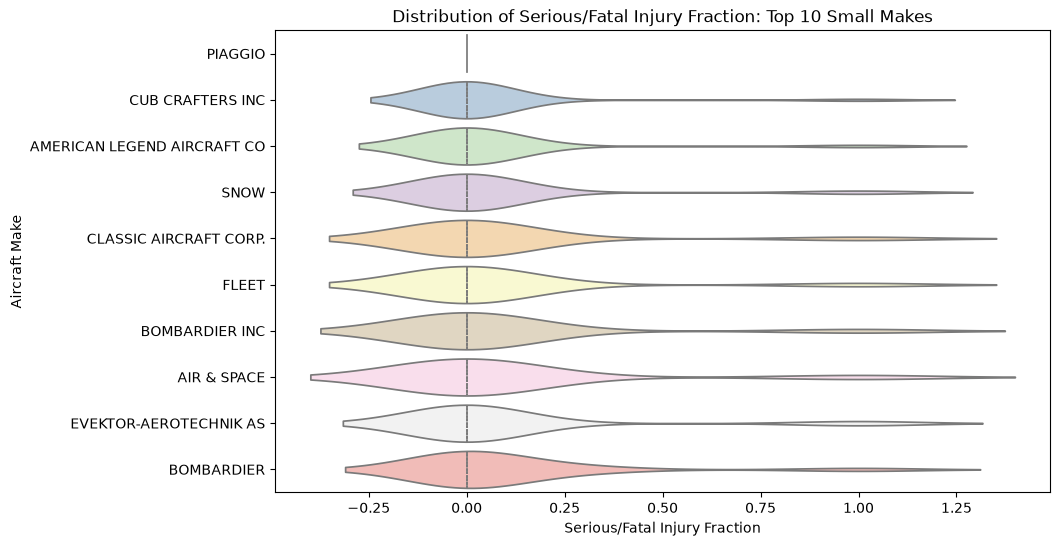

In [19]:
top10_small_makes = small_make_injury.head(10).index
df_small_top10 = df_small[df_small['Make'].isin(top10_small_makes)]

plt.figure(figsize=(10, 6))
sns.violinplot(data=df_small_top10, x='Serious_Fatal_Fraction', y='Make', order=top10_small_makes, palette='Pastel1', inner='quartile')
plt.title('Distribution of Serious/Fatal Injury Fraction: Top 10 Small Makes')
plt.xlabel('Serious/Fatal Injury Fraction')
plt.ylabel('Aircraft Make')
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\1579392247.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_large_top10, x='Serious_Fatal_Fraction', y='Make', order=top10_large_makes, jitter=True, size=8, palette='Set2')


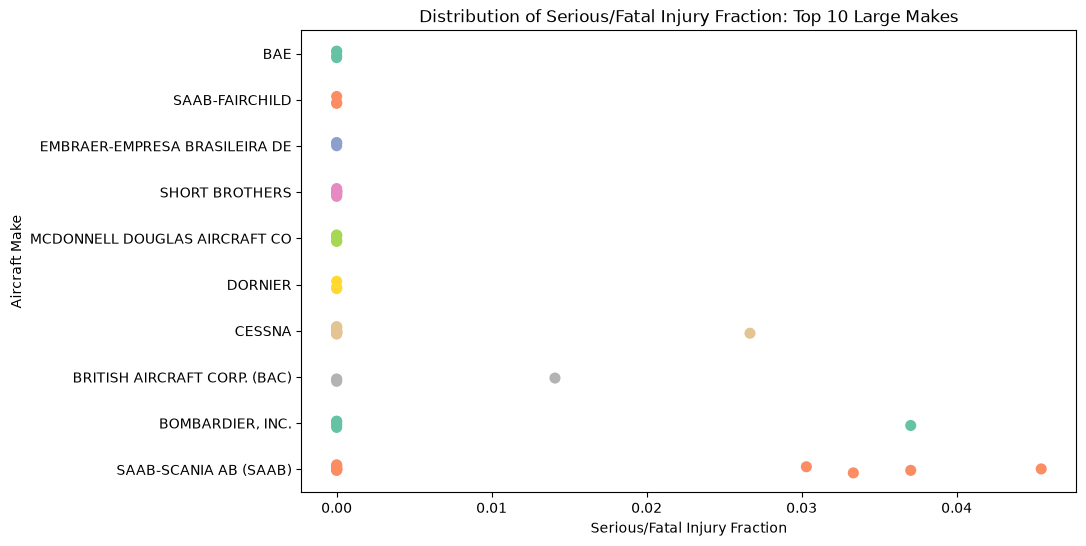

In [22]:
top10_large_makes = large_make_injury.head(10).index
df_large_top10 = df_large[df_large['Make'].isin(top10_large_makes)]

plt.figure(figsize=(10, 6))
sns.stripplot(data=df_large_top10, x='Serious_Fatal_Fraction', y='Make', order=top10_large_makes, jitter=True, size=8, palette='Set2')
plt.title('Distribution of Serious/Fatal Injury Fraction: Top 10 Large Makes')
plt.xlabel('Serious/Fatal Injury Fraction')
plt.ylabel('Aircraft Make')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [23]:
small_make_dest = df_small.groupby('Make')['Is.Destroyed'].agg(['mean', 'count']).query('count >= 10').sort_values('mean').head(15)
large_make_dest = df_large.groupby('Make')['Is.Destroyed'].agg(['mean', 'count']).query('count >= 3').sort_values('mean').head(15)

print("--- Lowest Destruction Rate: Small Aircraft Makes ---")
print(small_make_dest)

print("\n--- Lowest Destruction Rate: Larger Aircraft Makes ---")
print(large_make_dest)

--- Lowest Destruction Rate: Small Aircraft Makes ---
                                    mean  count
Make                                           
AIR CREATION                    0.000000     14
AIR & SPACE                     0.000000     10
AMERICAN LEGEND AIRCRAFT CO     0.000000     17
CHRISTEN INDUSTRIES INC         0.000000     16
CENTRAIR                        0.000000     11
CUB CRAFTERS                    0.000000     15
CUBCRAFTERS INC                 0.000000     21
CUB CRAFTERS INC                0.000000     20
EVEKTOR-AEROTECHNIK AS          0.000000     29
STEARMAN                        0.000000     22
REMOS AIRCRAFT GMBH             0.000000     13
MOONEY AIRPLANE CO INC          0.000000     10
UNIVERSAL STINSON               0.000000     11
GRUMMAN ACFT ENG COR-SCHWEIZER  0.017241     58
COSTRUZIONI AERONAUTICHE TECNA  0.030303     33

--- Lowest Destruction Rate: Larger Aircraft Makes ---
                                   mean  count
Make                       

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion of Findings and Recommendations

1. Small Aircraft

Some small aircraft makes show lower average serious/fatal injury fractions and destruction rates in the accident data. Insurers should consider these results when assessing risk while also checking sample sizes and other factors before setting premiums.

2. Larger Aircraft

Larger passenger aircraft may show lower injury fractions in the dataset potentially reflecting differences in aircraft design, crew training and safety procedures. Insurers should assess each model individually rather than assume all larger aircraft are safer.

3. Interpretation of the Plots and Statistics

The violin and strip plots show how injury fractions vary across aircraft makes and models. Some accidents have low injury fractions while others result in severe outcomes. Applying minimum sample-size thresholds helps reduce the influence of models with very few recorded accidents.

Conclusion

These findings can help insurers identify patterns in accident severity and support more informed risk assessments. However, accident records alone cannot establish which aircraft are safest since the analysis does not account for flight frequency or accidents that never occurred.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

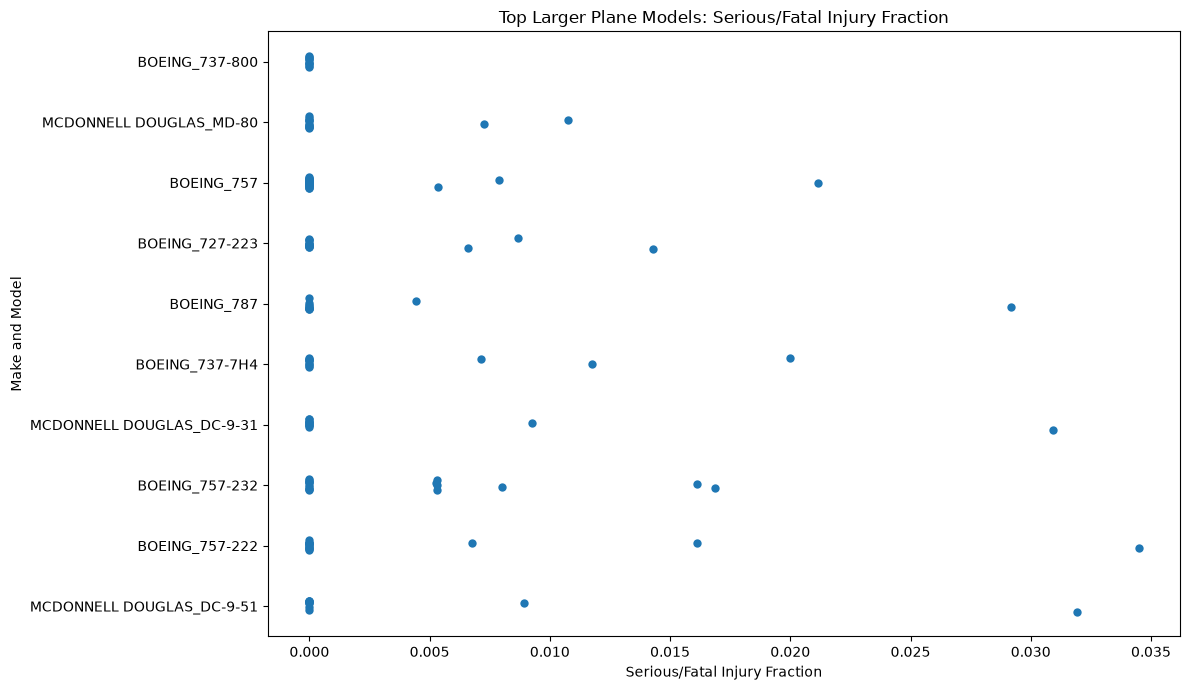

In [28]:


# Filter models with at least 10 instances
model_counts = df_large.groupby('Make.Model')['Make.Model'].transform('count')
df_model_large = df_large[model_counts >= 10].copy()

# Calculate injury fraction statistics
large_model_injury_stats = (
    df_model_large.groupby('Make.Model')['Serious_Fatal_Fraction']
    .agg(['mean', 'count'])
    .query('count >= 2')
)

# Select the 10 models with the lowest mean injury fraction
top_large_models = (
    large_model_injury_stats.sort_values('mean').head(10).index
)

df_large_top_models = df_model_large[
    df_model_large['Make.Model'].isin(top_large_models)
].dropna(subset=['Serious_Fatal_Fraction'])

# Plot strip chart
plt.figure(figsize=(12, 7))

sns.stripplot(
    data=df_large_top_models,
    x='Serious_Fatal_Fraction',
    y='Make.Model',
    order=top_large_models,
    jitter=True,
    size=6
)

plt.title('Top Larger Plane Models: Serious/Fatal Injury Fraction')
plt.xlabel('Serious/Fatal Injury Fraction')
plt.ylabel('Make and Model')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

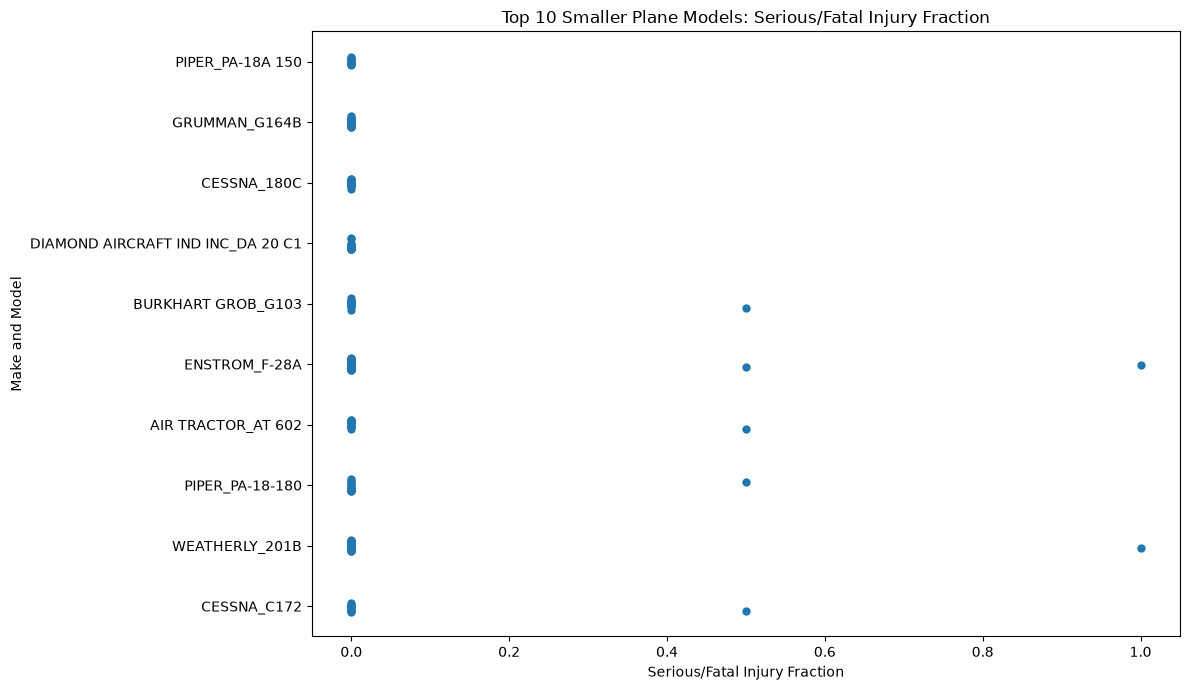

In [29]:


# Filter models with at least 10 instances
model_counts = df_small.groupby('Make.Model')['Make.Model'].transform('count')
df_model_small = df_small[model_counts >= 10].copy()

# Calculate injury fraction statistics
small_model_injury_stats = (
    df_model_small.groupby('Make.Model')['Serious_Fatal_Fraction']
    .agg(['mean', 'count'])
    .query('count >= 10')
)

# Select the 10 models with the lowest mean injury fraction
top10_small_models = (
    small_model_injury_stats.sort_values('mean').head(10).index
)

df_small_top10_models = df_model_small[
    df_model_small['Make.Model'].isin(top10_small_models)
].dropna(subset=['Serious_Fatal_Fraction'])

# Plot strip chart
plt.figure(figsize=(12, 7))

sns.stripplot(
    data=df_small_top10_models,
    x='Serious_Fatal_Fraction',
    y='Make.Model',
    order=top10_small_models,
    jitter=True,
    size=6
)

plt.title('Top 10 Smaller Plane Models: Serious/Fatal Injury Fraction')
plt.xlabel('Serious/Fatal Injury Fraction')
plt.ylabel('Make and Model')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Discussion of Specific Airplane Types

1. Smaller Airplane Models

Small aircraft models show different levels of injury severity. Many recorded accidents have low serious/fatal injury fractions but some incidents result in much more severe outcomes.

2. Larger Airplane Models

Some larger aircraft models also show low injury fractions across recorded accidents. However, this alone does not prove they are safer as aircraft design, accident circumstances and the number of flights can all affect the results.

3. Recommendations for Insurers

Insurers should assess individual aircraft models using injury patterns, accident history and sample sizes. These findings can support risk assessment but more data is needed to make reliable comparisons of overall safety.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\4001948473.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Weather.Condition', y='Serious_Fatal_Fraction', errorbar=None, palette='coolwarm')


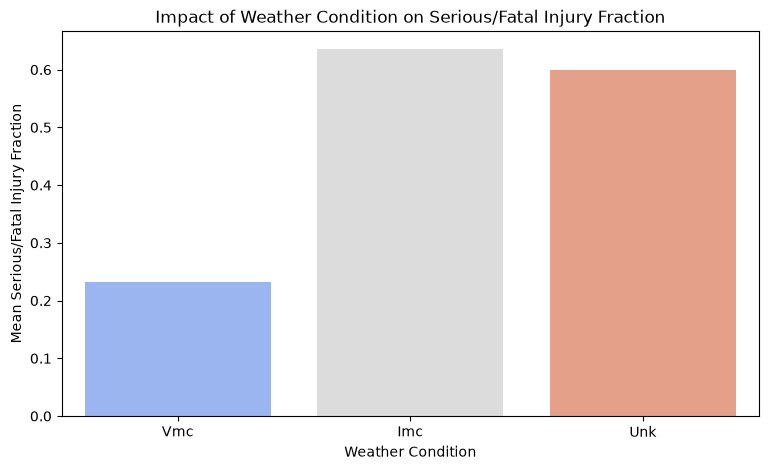

In [34]:
#WEATHER CONDITION

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='Weather.Condition', y='Serious_Fatal_Fraction', errorbar=None, palette='coolwarm')
plt.title('Impact of Weather Condition on Serious/Fatal Injury Fraction')
plt.xlabel('Weather Condition')
plt.ylabel('Mean Serious/Fatal Injury Fraction')
plt.savefig("weather_analysis.png", bbox_inches="tight", dpi=300)
plt.show()

Weather can affect visibility, pilot decisions and aircraft control. Understanding how it relates to injury severity can help insurers assess accident risks more accurately.

Analysis and Key Findings

The analysis compares the average serious/fatal injury fraction across different weather conditions.

- Visual Meteorological Conditions (VMC): Generally allow better visibility which helps pilots maintain control and avoid hazards.
- Instrument Meteorological Conditions (IMC): Poor visibility and adverse weather can make flying more difficult and increase the risk of severe accidents.

Implications for Insurers

1. Pilot training: Instrument-flying training may help pilots handle poor-visibility conditions more safely.
2. Risk assessment: Insurers should consider weather exposure when pricing policies, especially for operations in areas prone to fog, storms, or icing.

C:\Users\Joy Kamau\AppData\Local\Temp\ipykernel_5076\4023191895.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Broad.phase.of.flight', y='Is.Destroyed', errorbar=None, palette='magma')


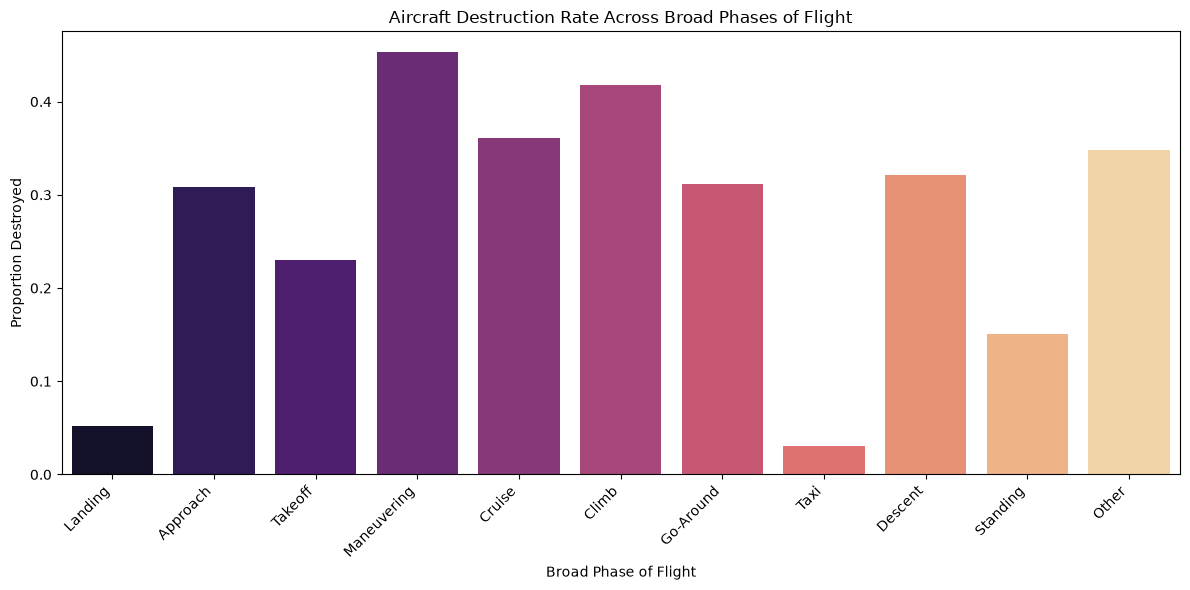

In [33]:
#PHASE OF FLIGHT

plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Broad.phase.of.flight', y='Is.Destroyed', errorbar=None, palette='magma')
plt.title('Aircraft Destruction Rate Across Broad Phases of Flight')
plt.xlabel('Broad Phase of Flight')
plt.ylabel('Proportion Destroyed')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("flight_phase_analysis.png", bbox_inches="tight", dpi=300)
plt.show()

The stage of flight when an accident occurs can affect its severity. This analysis examines accident rates, injury fractions and aircraft destruction across phases such as takeoff, cruise, approach and landing.

Key Findings

- Takeoff and landing: These phases account for many accidents including runway excursions and landing gear failures.
- Cruise and descent: Accidents may be less frequent but some can result in severe injuries and extensive aircraft damage.
- Maneuvering: Low-altitude maneuvers can be especially dangerous because pilots have less time and altitude to recover.

Implications for Insurers

Insurers can use these findings to identify high-risk flight phases and encourage better pilot training, improved safety systems and appropriate aircraft safety measures.